In [1]:
import json
import os
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


_NOTO_CJK_TTC = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if os.path.exists(_NOTO_CJK_TTC):
    matplotlib.font_manager.fontManager.addfont(_NOTO_CJK_TTC)
matplotlib.rcParams["font.family"] = "Noto Sans CJK JP"
matplotlib.rcParams["axes.unicode_minus"] = False

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TEXT_PRIMARY, TEXT_SECONDARY, GRID_COLOR = "#0b0b0b", "#52514e", "#e4e2dd"

METHOD_ORDER = ["rcb", "sisa", "guide_sr", "guts"]
METHOD_LABEL = {"rcb": "RCB", "sisa": "SISA-by-User", "guide_sr": "GUIDE-SR", "guts": "GUTS"}
METHOD_COLOR = {"rcb": "#009E73", "sisa": "#CC79A7", "guide_sr": "#0072B2", "guts": "#D55E00"}
METHOD_MARKER = {"rcb": "o", "sisa": "s", "guide_sr": "D", "guts": "X"}

DATA_DIR = Path("./figure_data")

def load_json(name):
    with open(DATA_DIR / name, encoding="utf-8") as f:
        return json.load(f)


def darken(hex_color, factor=0.65):
    r, g, b = (max(0, min(255, int(int(hex_color[i:i + 2], 16) * factor))) for i in (1, 3, 5))
    return f"#{r:02x}{g:02x}{b:02x}"


def style_axis(ax, labelsize):
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color(GRID_COLOR)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=labelsize)

In [2]:
PQ_DATA = load_json("partition_quality.json")["YJMob-14d"]
HPARAM_DATA = load_json("hparam_sensitivity.json")

In [3]:
def plot_hparam(data):
    k = 130
    ekw = dict(ecolor="black", elinewidth=0.8, capsize=2, alpha=0.7)
    brk = dict(marker=[(-1, -0.6), (1, 0.6)], markersize=8, linestyle="none",
               color=TEXT_SECONDARY, mec=TEXT_SECONDARY, mew=1, clip_on=False)

    def set_xlabels(ax, entry):
        ax.set_xticks(np.arange(len(entry["rows"])))
        for t in ax.set_xticklabels([r["label"] for r in entry["rows"]], color=TEXT_PRIMARY):
            if t.get_text() == entry["default"]:
                t.set_fontweight("bold")

    n_rows = len(data)
    row_h, row_gap, inner_gap = 1.25, 0.7, 0.083
    top_in, bottom_in = 0.81, 0.743
    fig_h = top_in + n_rows * row_h + (n_rows - 1) * row_gap + bottom_in
    fig = plt.figure(figsize=(9, fig_h))
    outer = fig.add_gridspec(n_rows, 2, width_ratios=[1.1, 1], hspace=row_gap / row_h, wspace=0.26,
                             top=1 - top_in / fig_h, bottom=bottom_in / fig_h)
    sub_h = (row_h - inner_gap) / 2
    for i, (name, entry) in enumerate(data.items()):
        rows = entry["rows"]
        col = {key: np.array([r[key] for r in rows], float).T for key in ("mrr", "acc1", "node", "user")}
        x = np.arange(len(rows))

        inner = outer[i, 0].subgridspec(2, 1, hspace=inner_gap / sub_h)
        ax_top, ax_bot = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
        for ax, ylim, ticks, ylabel in ((ax_top, (0.224, 0.234), [0.226, 0.230, 0.234], "MRR"),
                                        (ax_bot, (0.146, 0.156), [0.146, 0.150, 0.154], "Acc@1")):
            ax.bar(x - 0.18, col["mrr"][0], 0.36, yerr=col["mrr"][1], color=BLUE, edgecolor="none", error_kw=ekw, zorder=2)
            ax.bar(x + 0.18, col["acc1"][0], 0.36, yerr=col["acc1"][1], color=ORANGE, edgecolor="none", error_kw=ekw, zorder=2)
            ax.set_ylim(*ylim)
            ax.set_yticks(ticks)
            ax.set_ylabel(ylabel, fontsize=9, color=TEXT_SECONDARY)
            ax.set_xlim(-0.5, len(rows) - 0.5)
            ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8, zorder=0)
            style_axis(ax, 8)
        ax_top.spines["bottom"].set_visible(False)
        ax_top.tick_params(axis="x", bottom=False, labelbottom=False)
        ax_top.plot([0], [0], transform=ax_top.transAxes, **brk)
        ax_bot.plot([0], [1], transform=ax_bot.transAxes, **brk)
        set_xlabels(ax_bot, entry)
        ax_top.set_title(f"{name}: Performance", fontsize=10.5, color=TEXT_PRIMARY, fontweight="bold", pad=8)

        ax = fig.add_subplot(outer[i, 1])
        for key, color, marker in (("node", YELLOW, "s"), ("user", AQUA, "o")):
            vals, sds = col[key]
            ax.plot(x, vals, linewidth=2, color=color, alpha=0.88, zorder=3)
            ax.scatter(x, vals, marker=marker, s=9 ** 2, color=color, alpha=0.95,
                       edgecolor="white", linewidth=1.2, zorder=4)
            ax.errorbar(x, vals, yerr=sds, fmt="none", ecolor=darken(color),
                        elinewidth=1.0, capsize=2, alpha=0.6, zorder=3)
        ax.set_ylim(60, k + 5)
        ax.set_yticks([70, 100, k])
        ax.axhline(k, color=GRID_COLOR, linewidth=1.0, linestyle=":", zorder=0)
        ax.set_ylabel("Affected shards", fontsize=9, color=TEXT_SECONDARY)
        ax.set_xlim(-0.3, len(rows) - 0.7)
        set_xlabels(ax, entry)
        ax.set_title(f"{name}: Affected shards", fontsize=10.5, color=TEXT_PRIMARY, fontweight="bold", pad=8)
        ax.grid(color=GRID_COLOR, linewidth=0.8, zorder=0)
        style_axis(ax, 8)

    leg_y = 1 - 0.506 / fig_h
    fig.legend(handles=[Patch(facecolor=BLUE, label="MRR"), Patch(facecolor=ORANGE, label="Acc@1")],
               loc="lower center", bbox_to_anchor=(0.3, leg_y), ncol=2, frameon=False)
    fig.legend(handles=[Line2D([0], [0], color=c, lw=2, marker=m, markersize=8, markeredgecolor="white",
                               markeredgewidth=1.0, label=lab)
                        for c, m, lab in ((YELLOW, "s", "Node"), (AQUA, "o", "User"))],
               loc="lower center", bbox_to_anchor=(0.73, leg_y), ncol=2, frameon=False, handlelength=3.2)
    plt.show()

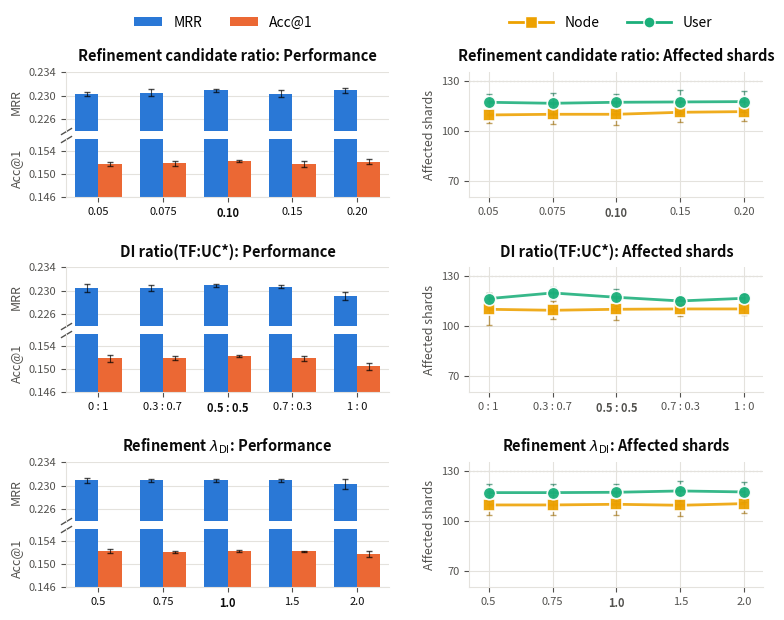

In [4]:
plot_hparam(HPARAM_DATA)

In [5]:
def plot_partition_quality(entry, dataset="YJMob-14d"):
    metrics = [("lambda_e", "Shards per Trajectory", "Number of shards", False),
               ("cstr", "Cross-Shard Transition", "CSTR ratio", True)]
    sparse_start, x_ticks, tick_muted = 11, [0, 2, 4, 6, 8, 10, 11, 12], "#7d7c78"
    days = entry["days"]
    n = len(metrics)
    ax_w, ax_h, gap = 4.5, 1.2, 0.62
    left_in, right_in, top_in, bottom_in = 0.6, 0.2, 0.35, 0.45
    fig_w = left_in + ax_w + right_in
    fig_h = top_in + n * ax_h + (n - 1) * gap + bottom_in
    fig = plt.figure(figsize=(fig_w, fig_h))
    marker_size = 6
    axes = []
    for i, (key, title, ylabel, is_ratio) in enumerate(metrics):
        y0 = fig_h - (top_in + i * (ax_h + gap) + ax_h)
        ax = fig.add_axes([left_in / fig_w, y0 / fig_h, ax_w / fig_w, ax_h / fig_h])
        axes.append(ax)
        ax.axvspan(sparse_start, days[-1] + 0.6, color=GRID_COLOR, alpha=0.45, lw=0, zorder=0)
        scale = 100 if is_ratio else 1
        for m in METHOD_ORDER:
            pts = [(d, v * scale, s * scale) for d, (v, s) in zip(days, entry["series"][m][key]) if v is not None]
            xs, vs, ss = [p[0] for p in pts], [p[1] for p in pts], [p[2] for p in pts]
            ax.plot(xs, vs, linewidth=1.3, color=METHOD_COLOR[m], alpha=0.88)
            if any(s > 0 for s in ss):
                ax.fill_between(xs, [v - s for v, s in zip(vs, ss)], [v + s for v, s in zip(vs, ss)],
                    color=METHOD_COLOR[m], alpha=0.18, lw=0, zorder=1)
                ax.errorbar(xs, vs, yerr=ss, fmt="none", ecolor=METHOD_COLOR[m], elinewidth=0.8, capsize=2,
                    capthick=0.8, alpha=0.9, zorder=2)
            ax.scatter(xs, vs, marker=METHOD_MARKER[m], s=marker_size ** 2, color=METHOD_COLOR[m],
                       alpha=0.95, edgecolor="white", linewidth=0.6, zorder=3)
        ax.set_title(title, color=TEXT_PRIMARY, fontsize=9, fontweight="bold", loc="left", pad=6)
        ax.set_ylabel(ylabel, fontsize=7.5, color=TEXT_SECONDARY, labelpad=2)
        if is_ratio:
            ax.annotate("(%)", xy=(0, 1), xycoords="axes fraction", xytext=(-3, 3), textcoords="offset points",
                        ha="right", va="bottom", fontsize=8, color=TEXT_SECONDARY)
            ax.set_ylim(0, 105)
            ax.set_yticks([0, 25, 50, 75, 100])
        else:
            ax.set_ylim(bottom=0)
        ax.set_xlabel(f"Day ({dataset})", fontsize=8, color=TEXT_SECONDARY, labelpad=1)
        ax.set_xlim(-0.6, days[-1] + 0.6)
        ax.set_xticks(x_ticks)
        ax.grid(color=GRID_COLOR, linewidth=0.8, zorder=0)
        style_axis(ax, 7)
        ax.set_xticklabels([str(t) for t in x_ticks])
        for lbl in ax.get_xticklabels():
            if lbl.get_text() == str(sparse_start):
                lbl.set_fontsize(6)
                lbl.set_color(tick_muted)
    fig.align_ylabels(axes)
    handles = [Line2D([0], [0], color=METHOD_COLOR[m], lw=1.3, marker=METHOD_MARKER[m], markersize=marker_size,
                      markeredgecolor="white", markeredgewidth=0.6, label=METHOD_LABEL[m]) for m in METHOD_ORDER]
    axes[0].legend(handles=handles, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=len(handles),
                   frameon=False, handlelength=1.7, fontsize=6, borderaxespad=0.1, columnspacing=0.9,
                   handletextpad=0.4, markerscale=0.85)
    plt.show()

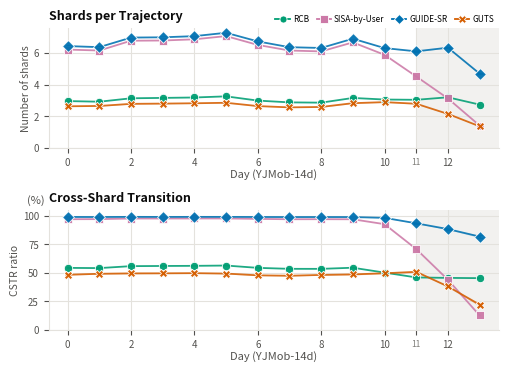

In [6]:
plot_partition_quality(PQ_DATA)